# Module 2 — Advanced Cleaning

**By the end of this notebook, you will be able to:**
- Explain why a per-city cleaning strategy that works on two well-populated cities can silently fail on a much smaller one
- Decide when a column should be dropped rather than filled, based on how much of it is actually missing
- Apply that decision *before* filling, and know why the order matters

**Context:** Session 2 worked with two cities picked to make a manual train/test split easy to reason about: Kampala (5596 rows) and Nairobi (1500 rows), capped at 1200 rows each. The full dataset has two more cities — Lagos (852 rows) and Bujumbura (only 123 rows) — and nothing capped. This module works with all four, uncapped, and finds out why `fill_missing_by_city` alone is not enough once a city gets this small.

In [1]:
from pathlib import Path
import sys

# Make the project's src/ package importable even if Jupyter starts in another folder/kernel.
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "src" / "air_quality").is_dir():
        sys.path.insert(0, str(candidate / "src"))
        break

from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

from air_quality import data, evaluation, features
from air_quality.workflows import DEFAULT_COLUMNS

ALL_CITIES = ["Kampala", "Nairobi", "Lagos", "Bujumbura"]

train_df, _ = data.load_datasets()
train_df["city"].value_counts()

city
Kampala      5596
Nairobi      1500
Lagos         852
Bujumbura     123
Name: count, dtype: int64

## The real imbalance

Session 2 used two cities specifically because they are both large enough for a manual split to be readable. `value_counts()` above shows what the other two look like: Lagos has roughly a third of Nairobi's rows, and Bujumbura has barely more than a hundred — 45x fewer than Kampala. Any per-city operation, like filling missing values city by city, has 45x less data to work with there.

**Exercise:** Call `data.restrict_to_scope(train_df, ALL_CITIES, DEFAULT_COLUMNS)` — no `max_rows_per_city` this time, since you want the real imbalance, not a capped-down version of it.

In [2]:
# TODO 1: scope train_df to ALL_CITIES and DEFAULT_COLUMNS, without
# capping rows per city
scoped = train_df[train_df["city"].isin(ALL_CITIES)][DEFAULT_COLUMNS]
scoped

,city,date,hour,site_latitude,site_longitude,pm2_5,sulphurdioxide_so2_column_number_density,carbonmonoxide_co_column_number_density,nitrogendioxide_no2_column_number_density,formaldehyde_tropospheric_hcho_column_number_density,uvaerosolindex_absorbing_aerosol_index,ozone_o3_column_number_density,uvaerosollayerheight_aerosol_height,cloud_cloud_fraction
0,Lagos,2023-10-25,13,6.532570,3.399360,12.015000,NaN,NaN,NaN,NaN,0.052301,0.122055,NaN,NaN
1,Lagos,2023-11-02,12,6.532570,3.399360,42.267200,NaN,0.045475,NaN,0.000214,-0.315206,0.116975,NaN,NaN
2,Lagos,2023-11-03,13,6.532570,3.399360,39.450741,NaN,NaN,NaN,NaN,1.097816,0.117559,NaN,0.756392
3,Lagos,2023-11-08,14,6.532570,3.399360,10.537600,NaN,NaN,NaN,NaN,0.591543,0.118412,NaN,NaN
4,Lagos,2023-11-09,13,6.532570,3.399360,19.431731,0.000267,0.049045,0.000097,0.000100,0.069669,0.117899,NaN,0.226141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8066,Nairobi,2024-01-17,10,-1.268877,36.819139,21.086071,NaN,NaN,NaN,NaN,-1.670265,0.104364,NaN,NaN
8067,Nairobi,2024-01-24,11,-1.268877,36.819139,17.110000,-0.000563,0.034113,0.000065,0.000116,-0.200583,0.106309,NaN,NaN
8068,Nairobi,2024-01-25,11,-1.268877,36.819139,15.080000,NaN,0.028830,NaN,0.000157,-0.539302,0.108092,NaN,NaN
8069,Nairobi,2024-01-26,10,-1.268877,36.819139,18.026750,-0.000188,0.033844,0.000064,0.000363,-1.049273,0.110403,NaN,NaN


## Missing values, by city this time

Session 2's discovery notebook already showed you a per-city missing-value heatmap, on two cities. Reapply the exact same pattern here, on `scoped` — only the number of cities changed.

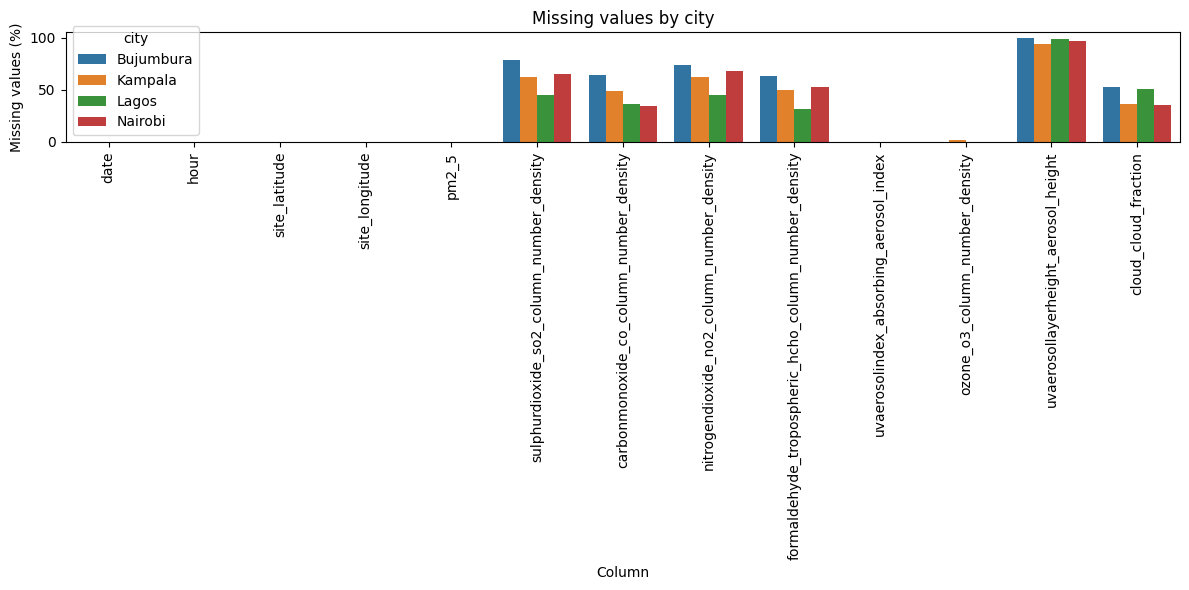

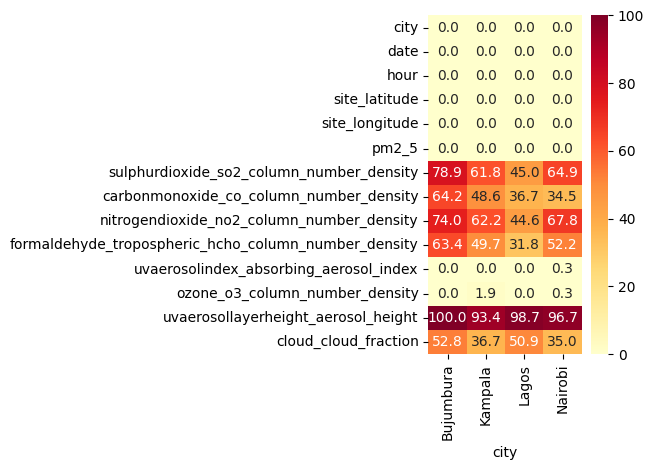

In [3]:
# TODO 2: percentage of missing values per column, broken down by city
# — same pattern as the discovery notebook's missing-values heatmap
import seaborn as sns

missing_by_city = (
    scoped
    .drop(columns="city")
    .isna()
    .assign(city=scoped["city"].to_numpy())
    .groupby("city")
    .mean()
    .mul(100)
)

plot_data = (
    missing_by_city
    .reset_index()
    .melt(id_vars="city", var_name="column", value_name="missing_pct")
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x="column",
    y="missing_pct",
    hue="city",
    ax=ax,
)

ax.set_ylabel("Missing values (%)")
ax.set_xlabel("Column")
ax.set_title("Missing values by city")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

missing_by_city = scoped.isna().groupby(scoped["city"]).mean() * 100
ax = sns.heatmap(missing_by_city.T, annot=True, fmt=".1f", cmap="YlOrRd")
ax.tick_params(axis='x', labelrotation=90)  # rotation des labels de l'axe X
plt.tight_layout()
plt.show()

**Look at `uvaerosollayerheight_aerosol_height`.** It was already the most-missing column in Session 2 (93-97% missing in Kampala/Nairobi) — high, but `fill_missing_by_city`'s forward/backward-fill could still work with the few values that did exist in each city. What does the heatmap show for Bujumbura?

## Why forward/backward-fill breaks down

`fill_missing_by_city` (Session 2, `data.py`) fills each city using only that city's own values, sorted by date — it never borrows a value from another city. If a city has **zero** non-missing values for a column, there is nothing to forward- or backward-fill from: the column stays entirely missing for that city's rows.

Bujumbura is missing `uvaerosollayerheight_aerosol_height` **100% of the time**. Apply the fill exactly as Session 2 did and see what remains.

In [4]:
# Given: apply the Session 2 fill as-is, across all four cities this time
fillable_columns = [c for c in scoped.columns if c not in ("city", "date")]
naively_filled = data.fill_missing_by_city(scoped, fillable_columns)
naively_filled.isna().sum()[naively_filled.isna().sum() > 0]

uvaerosollayerheight_aerosol_height    123
dtype: int64

123 rows — every single Bujumbura row — still have a missing value in that column. Nothing stops it from silently reaching the model. See what that actually does: train on Kampala, evaluate on Bujumbura, using this naively-filled data.

In [5]:
# Given: this is expected to fail — the point is to see the exact error
enriched = features.add_temporal_features(naively_filled)
train_split = enriched[enriched["city"] == "Kampala"]
test_split = enriched[enriched["city"] == "Bujumbura"]
feature_cols = features.feature_columns(enriched)

try:
    evaluation.evaluate_manual_split(LinearRegression(), train_split, test_split, feature_cols)
except ValueError as error:
    print("Training on Kampala, evaluating on Bujumbura crashed:")
    print(error)

Training on Kampala, evaluating on Bujumbura crashed:
Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


## The fix: drop before filling

The problem is not the filling strategy — it is trying to fill a column that has no data at all in a given city. The right move is to drop columns that are missing **too much data overall** *before* filling the rest per city, not after.

Open `src/air_quality/data.py` and complete the two functions in the "Session 3 — optional modules" section at the bottom of the file: `columns_above_missing_threshold` and `drop_columns`. Their docstrings specify the exact contract, and `tests/test_data_advanced.py` specifies the exact expected behavior — read it the same way you read `tests/test_data.py` in Session 2's Transfer to Python activity. Run `uv run pytest tests/test_data_advanced.py -v` until both pass, then come back here.

**Exercise:** Use `data.columns_above_missing_threshold(scoped, threshold=0.7)` to find the columns to drop, then `data.drop_columns` to remove them from `scoped`. Fill what remains with `data.fill_missing_by_city`, and confirm no missing values remain.

In [6]:
# TODO 3: drop columns missing more than 70% of the time, then fill the
# rest per city, and confirm nothing is missing anymore
columns_to_drop = data.columns_above_missing_threshold(scoped, threshold=0.7)
cleaned = data.drop_columns(scoped, columns_to_drop)

fillable_columns = [
    column for column in cleaned.columns
    if column not in ("city", "date")
]
cleaned = data.fill_missing_by_city(cleaned, fillable_columns)

cleaned.isna().sum()

city                                                    0
date                                                    0
hour                                                    0
site_latitude                                           0
site_longitude                                          0
pm2_5                                                   0
sulphurdioxide_so2_column_number_density                0
carbonmonoxide_co_column_number_density                 0
nitrogendioxide_no2_column_number_density               0
formaldehyde_tropospheric_hcho_column_number_density    0
uvaerosolindex_absorbing_aerosol_index                  0
ozone_o3_column_number_density                          0
cloud_cloud_fraction                                    0
dtype: int64

## Confirming the fix

Rerun the same Kampala → Bujumbura evaluation as before, this time on `cleaned` instead of `naively_filled`.

In [8]:
# Given: same evaluation as before, on the cleaned data this time
enriched = features.add_temporal_features(cleaned)
train_split = enriched[enriched["city"] == "Kampala"]
test_split = enriched[enriched["city"] == "Bujumbura"]
feature_cols = features.feature_columns(enriched)

metrics = evaluation.evaluate_manual_split(LinearRegression(), train_split, test_split, feature_cols)
metrics

{'rmse': np.float64(19.176455068783216),
 'mae': 12.02954101801658,
 'r2': 0.2580145734252217}

**Continue on the site:** [Module 2 — Advanced Cleaning](https://hub.imt-atlantique.fr/datascience-toolkit/session3/practical_2/)